# EDA_Retail_Sales_Analysis 

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load DATASET

In [8]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")

print(df.head())

Dataset loaded successfully!
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


#  DATASET EXPLORATION

In [6]:
print("Number of rows and columns:")
print(df.shape)

print("Column names:")
print(df.columns)

print("Data types:")
print(df.dtypes)

print("Dataset information:")
df.info()

print("Statistical summary:")
print(df.describe())

print("Categorical summary:")
print(df.describe(include="object"))

Number of rows and columns:
(541909, 8)
Column names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   C

# MISSING VALUES

In [9]:
print("Missing values in each column:")

print(df.isnull().sum())

print("Missing percentage:")

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

print(missing_percentage)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Missing percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


#  MISSING VALUES CHART

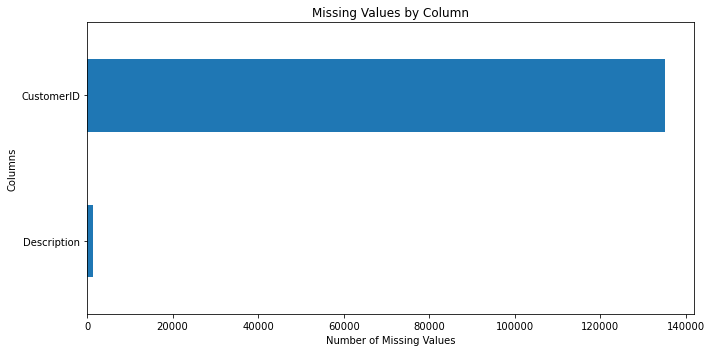

In [12]:
 from pathlib import Path
import matplotlib.pyplot as plt

CHART_DIR = Path("outputs/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

missing = df.isnull().sum()
missing = missing[missing > 0]

if not missing.empty:
  plt.figure(figsize=(10, 5))
  missing.sort_values().plot(kind="barh")
  plt.title("Missing Values by Column")
  plt.xlabel("Number of Missing Values")
  plt.ylabel("Columns")
  plt.tight_layout()
  plt.savefig(CHART_DIR / "missing_values.png")
  plt.show()
else:
  print("No missing values found.")

# 5. DUPLICATE RECORDS

In [14]:
print("Total duplicate records:")

print(df.duplicated().sum())

# Remove exact duplicate rows

df = df.drop_duplicates()

print("Shape after removing duplicates:")

print(df.shape)

Total duplicate records:
5268
Shape after removing duplicates:
(536641, 8)


# 6. DATA CLEANING

In [15]:
 
# Convert date column

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Convert numeric columns

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"],
    errors="coerce"
)

# Clean text columns

df["Description"] = (
    df["Description"]
    .astype("string")
    .str.strip()
)

df["Country"] = (
    df["Country"]
    .astype("string")
    .str.strip()
)

print(df.dtypes)

InvoiceNo              object
StockCode              object
Description            string
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                string
dtype: object


# 7. INVALID RECORDS AND RETURNS

In [16]:
 
print(
    "Cancellation invoices:",
    df["InvoiceNo"]
    .str.startswith("C", na=False)
    .sum()
)

print(
    "Negative quantities:",
    (df["Quantity"] < 0).sum()
)

print(
    "Zero or negative prices:",
    (df["UnitPrice"] <= 0).sum()
)

# Keep a separate copy for investigating
# returns and cancellations.

quality_df = df[
    df["InvoiceDate"].notna()
    & df["Description"].notna()
    & df["UnitPrice"].gt(0)
].copy()

# Prepare positive sales data.

sales_df = quality_df[
    ~quality_df["InvoiceNo"].str.startswith(
        "C", na=False
    )
    & quality_df["Quantity"].gt(0)
].copy()

print("Positive sales records:", len(sales_df))

Cancellation invoices: 9251
Negative quantities: 10587
Zero or negative prices: 2512
Positive sales records: 524878


# 8. FEATURE ENGINEERING

In [17]:
 
# Calculate revenue

sales_df["Revenue"] = (
    sales_df["Quantity"]
    * sales_df["UnitPrice"]
)

# Extract year

sales_df["Year"] = (
    sales_df["InvoiceDate"].dt.year
)

# Extract month

sales_df["Month"] = (
    sales_df["InvoiceDate"].dt.month
)

# Extract month name

sales_df["MonthName"] = (
    sales_df["InvoiceDate"].dt.strftime("%B")
)

# Extract day

sales_df["Day"] = (
    sales_df["InvoiceDate"].dt.day
)

# Extract weekday

sales_df["DayOfWeek"] = (
    sales_df["InvoiceDate"].dt.day_name()
)

# Extract hour

sales_df["Hour"] = (
    sales_df["InvoiceDate"].dt.hour
)

print(sales_df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  Year  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  2010   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  2010   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010   

   Month MonthName  Day  DayOfWeek  Hour  
0     12  December    1  Wednesday     8  
1     

# 9. OUTLIER DETECTION

In [18]:
 
def detect_outliers(data, column):

    Q1 = data[column].quantile(0.25)

    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_limit)
        |
        (data[column] > upper_limit)
    ]

    print("\nColumn:", column)

    print("Lower limit:", lower_limit)

    print("Upper limit:", upper_limit)

    print("Outliers:", len(outliers))

    return outliers


quantity_outliers = detect_outliers(
    sales_df, "Quantity"
)

price_outliers = detect_outliers(
    sales_df, "UnitPrice"
)

revenue_outliers = detect_outliers(
    sales_df, "Revenue"
)


Column: Quantity
Lower limit: -14.0
Upper limit: 26.0
Outliers: 27111

Column: UnitPrice
Lower limit: -3.0700000000000003
Upper limit: 8.45
Outliers: 37827

Column: Revenue
Lower limit: -16.800000000000004
Upper limit: 38.400000000000006
Outliers: 42624


# OUTLIER BOXPLOT

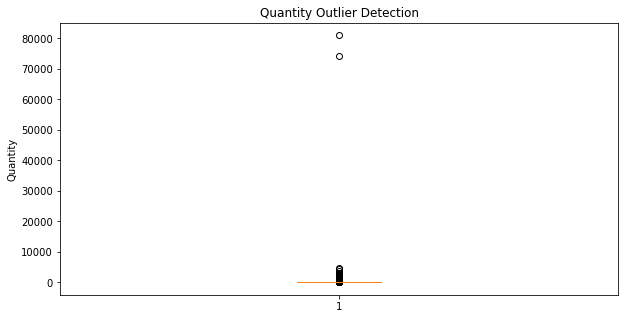

In [19]:
 
plt.figure(figsize=(10, 5))

plt.boxplot(
    sales_df["Quantity"],
    vert=True
)

plt.title("Quantity Outlier Detection")

plt.ylabel("Quantity")

plt.savefig(
    CHART_DIR / "outlier_boxplot.png"
)

plt.show()

# 10. BUSINESS KPIs

In [20]:
 
total_revenue = sales_df["Revenue"].sum()

total_orders = (
    sales_df["InvoiceNo"].nunique()
)

total_customers = (
    sales_df["CustomerID"].nunique()
)

total_products = (
    sales_df["StockCode"].nunique()
)

total_quantity = (
    sales_df["Quantity"].sum()
)

average_order_value = (
    total_revenue / total_orders
)

print("TOTAL REVENUE:", total_revenue)

print("TOTAL ORDERS:", total_orders)

print("TOTAL CUSTOMERS:", total_customers)

print("TOTAL PRODUCTS:", total_products)

print("TOTAL QUANTITY:", total_quantity)

print("AVERAGE ORDER VALUE:", average_order_value)

TOTAL REVENUE: 10642110.804
TOTAL ORDERS: 19960
TOTAL CUSTOMERS: 4338
TOTAL PRODUCTS: 3922
TOTAL QUANTITY: 5572420
AVERAGE ORDER VALUE: 533.1718839679359


# 11. MONTHLY SALES ANALYSIS

In [33]:
 
monthly_sales = (
    sales_df.groupby("MonthName")["Revenue"]
    .sum()
)

# print(monthly_sales)
# sales_df["YearMonth"] = (
#     sales_df["InvoiceDate"]
#     .dt.to_period("M")
#     .astype(str)
# )

# monthly_sales = (
#     sales_df.groupby("YearMonth")["Revenue"]
#     .sum()
#     .sort_index()
# )

print(monthly_sales)

MonthName
April         536968.491
August        757841.380
December     1459243.060
February      522545.560
January       689811.610
July          718076.121
June          760547.010
March         716215.260
May           769296.610
November     1503866.780
October      1151263.730
September    1056435.192
Name: Revenue, dtype: float64


# Create a line chart

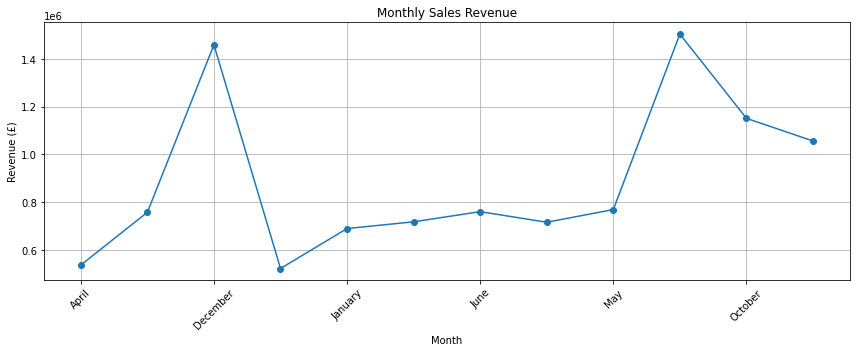

In [23]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Revenue")

plt.xlabel("Month")

plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "monthly_revenue.png"
)

plt.show()

# 12. PRODUCT ANALYSIS

In [24]:
 
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


# Create a bar chart

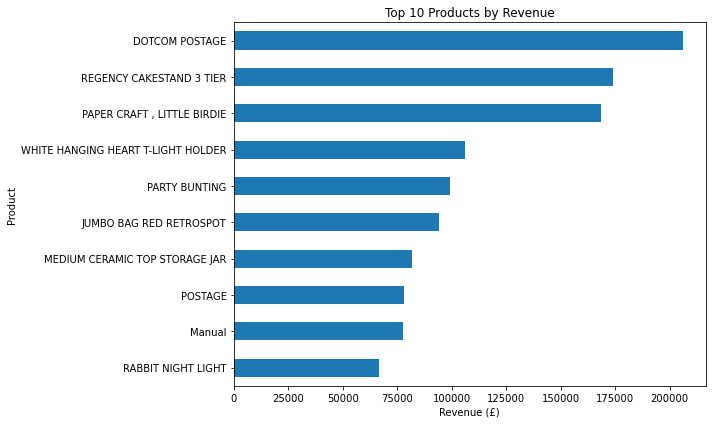

In [25]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Revenue")

plt.xlabel("Revenue (£)")

plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "top_products.png"
)

plt.show()

In [26]:
top_quantity = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_quantity)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


# 13. COUNTRY ANALYSIS

In [27]:
 
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10))

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


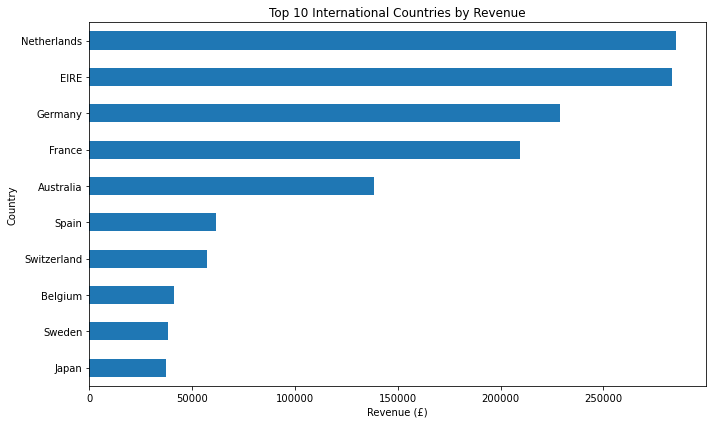

In [28]:
international_sales = (
    country_sales
    .drop("United Kingdom", errors="ignore")
    .head(10)
)

international_sales.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title(
    "Top 10 International Countries by Revenue"
)

plt.xlabel("Revenue (£)")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "country_revenue.png"
)

plt.show()

# 14. CUSTOMER ANALYSIS

In [29]:
 
customer_data = sales_df.dropna(
    subset=["CustomerID"]
)

customer_summary = (
    customer_data
    .groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),

        Total_Orders=("InvoiceNo", "nunique"),

        Total_Quantity=("Quantity", "sum")
    )
)

customer_summary = customer_summary.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(customer_summary.head(10))

            Total_Revenue  Total_Orders  Total_Quantity
CustomerID                                             
14646.0         280206.02            73          196915
18102.0         259657.30            60           64124
17450.0         194390.79            46           69973
16446.0         168472.50             2           80997
14911.0         143711.17           201           80240
12415.0         124914.53            21           77374
14156.0         117210.08            55           57768
17511.0          91062.38            31           64549
16029.0          80850.84            63           40108
12346.0          77183.60             1           74215


In [30]:
customer_summary["Average_Order_Value"] = (
    customer_summary["Total_Revenue"]
    / customer_summary["Total_Orders"]
)

print(customer_summary.head(10))

            Total_Revenue  Total_Orders  Total_Quantity  Average_Order_Value
CustomerID                                                                  
14646.0         280206.02            73          196915          3838.438630
18102.0         259657.30            60           64124          4327.621667
17450.0         194390.79            46           69973          4225.886739
16446.0         168472.50             2           80997         84236.250000
14911.0         143711.17           201           80240           714.980945
12415.0         124914.53            21           77374          5948.310952
14156.0         117210.08            55           57768          2131.092364
17511.0          91062.38            31           64549          2937.496129
16029.0          80850.84            63           40108          1283.346667
12346.0          77183.60             1           74215         77183.600000


# 15. EXPORT RESULTS

In [32]:
 from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Save cleaned sales data

sales_df.to_csv(
    OUTPUT_DIR / "cleaned_sales_data.csv",
    index=False
)

# Save monthly sales

monthly_sales.to_csv(
    OUTPUT_DIR / "monthly_sales_summary.csv"
)

# Save country sales

country_sales.to_csv(
    OUTPUT_DIR / "country_sales_summary.csv"
)

# Save customer summary

customer_summary.to_csv(
    OUTPUT_DIR / "customer_summary.csv"
)

print("All results exported successfully!")

All results exported successfully!
